# 09. A grande final: os filtros entregues

| Filtro | Onde brilha | Configuração |
|---|---|---|
| **Especialista** | esta caixa (farmer-d): o menor custo nos 20 folds | Stacking 7 do algoritmo genético (D8) |
| **Stacking 8** | o melhor stacking fora da caixa (regra D10) | Stacking 7 padrão + TabPFN-3.5-Plus como 8º membro |
| **TabPFN-3.5 sozinho** | o filtro mais robusto fora da caixa, sem nenhum ajuste | modelo de fundação para tabelas (Prior Labs) |
| **Stacking 7 padrão** | roda sem internet e sem chave (usado na demo) | um modelo de cada família, hiperparâmetros padrão |
| **Linha de base** | referência simples | LinearSVC com TF-IDF log |
| Não filtrar | referência trivial: todo spam passa, nenhum e-mail real se perde | — |

Todos usam o **limiar de custo**: perder 1 e-mail real custa o mesmo que receber 9 spams. O TCR (*total cost
ratio*, Androutsopoulos et al., 2000) é o custo de não filtrar dividido pelo custo do filtro: acima de 1, o filtro
compensa. Este script treina os filtros nos 5172 e-mails, reúne os números das quatro avaliações e grava
`resultados/metricas_finais.json`, a fonte única de README, notebook, apresentações e demo.

(As chaves do JSON guardam os nomes antigos: `generalista` = Stacking 8 e `generalista_sem_chave` = Stacking 7
padrão. Ver D11 no registro de decisões.)

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/felipe44776-eseg/filtro-spam-stacking-enron/blob/main/notebooks/09_modelos_finais.ipynb)

**No Google Colab:** rode tudo (*Ambiente de execução → Executar tudo*). Na primeira vez, a célula abaixo baixa o
projeto, instala os pacotes e **reinicia o ambiente**; quando o Colab reconectar, use *Executar tudo* de novo.
No computador, ela não faz nada (siga o [INSTALACAO.md](https://github.com/felipe44776-eseg/filtro-spam-stacking-enron/blob/main/INSTALACAO.md)).

In [1]:
# Google Colab: prepara o ambiente na primeira execução. No computador, esta célula não faz nada.
import os, subprocess, sys
if "google.colab" in sys.modules:
    PROJETO = "/content/filtro-spam-stacking-enron"
    if not os.path.isdir(PROJETO):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/felipe44776-eseg/filtro-spam-stacking-enron.git", PROJETO], check=True)
    os.chdir(PROJETO)
    sys.path.insert(0, PROJETO)
    MARCA = "/content/.spamfilter_instalado"
    if not os.path.exists(MARCA):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
        open(MARCA, "w").close()
        print("Pacotes instalados. O Colab vai reiniciar o ambiente: quando reconectar, use Executar tudo de novo.")
        os.kill(os.getpid(), 9)

In [2]:
import datetime as dt
import json
import os
import platform
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict

import spamfilter
from spamfilter import caminhos, dados, externo, graficos, metricas, modelos, publicados, saidas
from spamfilter.dados import SEED
from spamfilter.filtro import FiltroStacking
from spamfilter.motor import Motor

base = dados.carregar()
m = Motor(base, log=lambda *a: None)
CONF = m.adicionar_divisoes([201, 202, 203, 204])
m.adicionar_teste_trancado()
Xext, yext, _ = externo.carregar_externo(base)
m.adicionar_externo(Xext)
ESP, PAD = modelos.STACKING7_ESPECIALISTA, modelos.STACKING7_PADRAO
TABN = caminhos.EXPERIMENTOS / "05_tabpfn" / "cache_tabpfn" / "nuvem"

## 1. Treinar e salvar os filtros (nos 5172 e-mails)

In [3]:
PASTA = caminhos.RESULTADOS / "modelos"
def ztr_externo(cfg):
    return np.column_stack([np.load(m.arquivo("externo", f, cfg[i]))["ztr"] for i, f in enumerate(modelos.FAMILIAS)])

FILTROS = {}
for nome, cfg in [("especialista", ESP), ("stacking7_padrao", PAD)]:
    arq = PASTA / f"{nome}.joblib"
    if not arq.exists():                       # primeiro tenta a Release do GitHub; sem internet, treina (cerca de 2 min)
        try:
            publicados.garantir(nome)
        except Exception as e:
            print(f"{nome}: sem download ({type(e).__name__}); treinando nos 5172 e-mails")
            FiltroStacking.treinar(nome, cfg, base, ztr_externo(cfg)).salvar(arq)
    FILTROS[nome] = FiltroStacking.carregar(arq)
    print(f"{nome}: limiar de custo {FILTROS[nome].limiar:.3f} | arquivo {arq.stat().st_size / 2**20:.1f} MB")

# Stacking 8: os membros do Stacking 7 padrão + a nota do TabPFN; o meta-modelo tem 8 entradas.
ztr8 = np.column_stack([ztr_externo(PAD), np.load(TABN / "externo.npz")["ztr"]])
meta8 = modelos.meta(modelos.META_C[PAD[-1]])
oof8 = cross_val_predict(meta8, ztr8, base.y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
meta8.fit(ztr8, base.y)
generalista = dict(nome="generalista_stacking8", membros="stacking7_padrao.joblib", oitavo_membro="TabPFN-3.5-Plus (nuvem, tabpfn-client)",
                   meta_modelo=meta8, limiar=float(metricas.limiar_custo(oof8, base.y)))
import joblib
# Os .joblib só são gravados se faltarem: os publicados na Release v1.0 são conferidos pelo sha256 (spamfilter.publicados).
if not (PASTA / "generalista_stacking8.joblib").exists():
    joblib.dump(generalista, PASTA / "generalista_stacking8.joblib", compress=3)
ztr_l = np.load(m.arquivo("externo", "LinearSVC", modelos.LINEARSVC_PADRAO))["ztr"]
limiar_lsvc = float(metricas.limiar_custo(ztr_l, base.y))
if not (PASTA / "linha_de_base.joblib").exists():
    lsvc = modelos.construir("LinearSVC", modelos.LINEARSVC_PADRAO).fit(base.X, base.y)
    joblib.dump(dict(nome="linha_de_base_linearsvc", modelo=lsvc, limiar=limiar_lsvc), PASTA / "linha_de_base.joblib", compress=3)
limiar_tab = float(metricas.limiar_custo(np.load(TABN / "externo.npz")["ztr"], base.y))
print(f"generalista (Stacking 8): limiar {generalista['limiar']:.3f} | pesos do meta-modelo: "
      + ", ".join(f"{n} {w:+.2f}" for n, w in zip(modelos.FAMILIAS + ["TabPFN"], meta8[-1].coef_.ravel())))
# pesos do meta-modelo dos filtros entregues (treinados nos 5172 e-mails), sobre as notas padronizadas
PESOS = {"especialista": dict(zip(modelos.FAMILIAS, map(float, FILTROS["especialista"].meta_modelo[-1].coef_.ravel()))),
         "generalista_sem_chave": dict(zip(modelos.FAMILIAS, map(float, FILTROS["stacking7_padrao"].meta_modelo[-1].coef_.ravel()))),
         "generalista": dict(zip(modelos.FAMILIAS + ["TabPFN"], map(float, meta8[-1].coef_.ravel())))}
for k, w in PESOS.items():
    print(f"pesos do meta-modelo ({k}):", ", ".join(f"{f} {v:+.2f}" for f, v in w.items()))

especialista: limiar de custo 0.711 | arquivo 42.4 MB


stacking7_padrao: limiar de custo 0.807 | arquivo 26.8 MB
generalista (Stacking 8): limiar 0.881 | pesos do meta-modelo: Reg. Logística +0.91, SVM RBF +1.23, kNN cosseno +1.52, MLP -0.32, Naive Bayes -0.00, Extra Trees +0.28, LightGBM +1.02, TabPFN +1.55
pesos do meta-modelo (especialista): Reg. Logística +0.00, SVM RBF +2.75, kNN cosseno +1.54, MLP +0.14, Naive Bayes -0.05, Extra Trees +1.00, LightGBM +1.23
pesos do meta-modelo (generalista_sem_chave): Reg. Logística +0.94, SVM RBF +1.56, kNN cosseno +1.69, MLP -0.11, Naive Bayes +0.09, Extra Trees +0.92, LightGBM +1.24
pesos do meta-modelo (generalista): Reg. Logística +0.91, SVM RBF +1.23, kNN cosseno +1.52, MLP -0.32, Naive Bayes -0.00, Extra Trees +0.28, LightGBM +1.02, TabPFN +1.55


## 2. As quatro avaliações de cada filtro

In [4]:
def tab_nuvem(chave, te):
    z = np.load(TABN / f"{chave}.npz"); return z["ztr"], z[f"zte_{te}"]

def n_teste(chave, te):
    return len(yext[te]) if chave == "externo" else len(m.y_teste(chave)) if chave != "teste" else len(m.teste)

def prever(nome, chave, te="te"):
    if nome == "especialista":
        return m.prever_stacking(ESP, chave, te)
    if nome == "generalista":
        return m.prever_stacking(PAD, chave, te, extra=tab_nuvem(chave, te))
    if nome == "generalista_sem_chave":
        return m.prever_stacking(PAD, chave, te)
    if nome == "tabpfn":                       # TabPFN sozinho: limiar de custo nas notas out-of-fold do treino
        ztr, zte = tab_nuvem(chave, te); lim = metricas.limiar_custo(ztr, m.y_treino(chave))
        return zte, (zte > 0.5).astype(int), (zte > lim).astype(int)
    if nome == "nao_filtrar":
        k = n_teste(chave, te); return np.zeros(k), np.zeros(k, int), np.zeros(k, int)
    return m.prever_linearsvc(modelos.LINEARSVC_PADRAO, chave, te)

NOMES = ["especialista", "generalista", "tabpfn", "generalista_sem_chave", "linha_de_base", "nao_filtrar"]
POR_FOLD = {n: pd.DataFrame([metricas.metricas(m.y_teste(c), *prever(n, c)) for c in CONF], index=CONF) for n in NOMES}
cv20 = {n: POR_FOLD[n].mean().to_dict() for n in NOMES}
ext = {}
for n in NOMES:
    por = {b: metricas.metricas(yext[b], *prever(n, "externo", b)) for b in Xext}
    ext[n] = dict(pd.DataFrame(por).T.mean().to_dict(), por_base=por)
# O TCR de um conjunto de folds ou de caixas é a razão dos custos médios (a mesma média que o custo publicado),
# não a média das razões: custo médio de não filtrar ÷ custo médio do filtro.
for agregado in (cv20, ext):
    ref = agregado["nao_filtrar"]["custo_por_mil"]
    for n in NOMES:
        agregado[n]["tcr"] = ref / agregado[n]["custo_por_mil"] if agregado[n]["custo_por_mil"] > 0 else float("inf")
sa = {r["metodo"]: r for r in saidas.ler("08_terceira_base")["terceira_base"]["metodos"]}
MAPA_SA = {"especialista": "Stacking 7 especialista", "generalista": "Stacking 8 padrão (+TabPFN)", "tabpfn": "TabPFN-3.5-Plus sozinho",
           "generalista_sem_chave": "Stacking 7 padrão", "linha_de_base": "LinearSVC padrão", "nao_filtrar": "Não filtrar (referência)"}

### Nesta caixa: o stacking custa menos que o melhor modelo único?
Custo por mil nos 20 folds, t corrigido de Nadeau-Bengio (Holm) e teste bayesiano correlacionado
(equivalência = diferença menor que 3 por mil). Diferença negativa = o primeiro é mais barato.

                    A                     B     dif  ic95_lo  ic95_hi  reducao_relativa  p_holm  P_A_melhor  P_equivalentes
         especialista         linha_de_base -15.411  -30.119   -0.704             0.296   0.246       0.953           0.038
          generalista         linha_de_base -13.838  -30.132    2.456             0.266   0.457       0.910           0.068
generalista_sem_chave         linha_de_base -10.516  -26.405    5.372             0.202   0.728       0.833           0.122
         especialista generalista_sem_chave  -4.895  -15.950    6.159             0.118   1.000       0.638           0.286
          generalista generalista_sem_chave  -3.321  -15.895    9.252             0.080   1.000       0.521           0.326
               tabpfn         linha_de_base   3.565  -17.723   24.853            -0.069   1.000       0.263           0.215


                       MCC custo (20 folds)  PR-AUC (20 folds)  custo/mil (20 folds)  teste trancado: reais na lixeira  teste trancado: spams que passaram  custo/mil Enron2-6  custo/mil SpamAssassin
especialista                          0.962              0.998                36.618                               1.0                                10.0             207.650                2416.474
generalista                           0.956              0.998                38.192                               2.0                                13.0             138.496                1119.914
tabpfn                                0.922              0.997                55.594                               4.0                                27.0             125.995                 503.473
generalista_sem_chave                 0.955              0.997                41.513                               0.0                                17.0             177.453                1977.175
linha

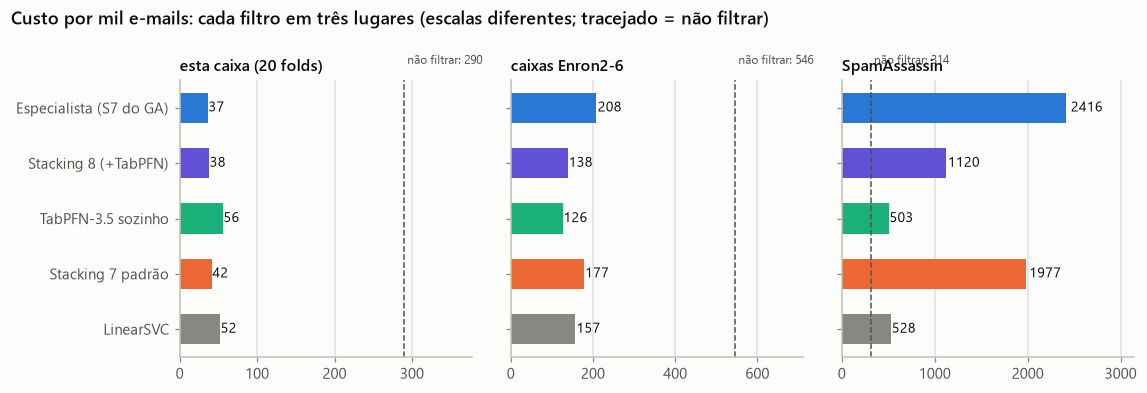

In [5]:
from spamfilter import estatistica
PC = pd.DataFrame({n: POR_FOLD[n]["custo_por_mil"] for n in NOMES})
PARES = [("especialista", "linha_de_base"), ("generalista", "linha_de_base"), ("generalista_sem_chave", "linha_de_base"),
         ("tabpfn", "linha_de_base"), ("especialista", "generalista_sem_chave"), ("generalista", "generalista_sem_chave")]
CMP = estatistica.comparar(-PC, PARES, 3310, 828, rope=3.0, runs=4)
CMP["dif"] = -CMP["dif"]; CMP["t"] = -CMP["t"]        # de volta ao sinal natural: negativo = A mais barato
ic = {(a, b): estatistica.ic_corrigido(PC[a], PC[b], 3310, 828) for a, b in PARES}
CMP["ic95_lo"] = [ic[(a, b)][1] for a, b in zip(CMP.A, CMP.B)]; CMP["ic95_hi"] = [ic[(a, b)][2] for a, b in zip(CMP.A, CMP.B)]
CMP["reducao_relativa"] = [-d / PC[b].mean() for d, b in zip(CMP.dif, CMP.B)]
print(CMP[["A", "B", "dif", "ic95_lo", "ic95_hi", "reducao_relativa", "p_holm", "P_A_melhor", "P_equivalentes"]].round(3).to_string(index=False))

# Base de teste trancada. Os 7 membros e o LinearSVC já estão no cache (usos 1 e 2, experimentos 02 e 03).
# O Stacking 8 precisa do TabPFN treinado nos 80% (5 treinos internos + 1 final): 3º uso, só para relatar (D10 já decidida).
# O TabPFN sozinho usa as mesmas notas do 3º uso; relatá-lo é o 4º uso, também só de relato (D11): nada é escolhido.
arq_tt = caminhos.RESULTADOS / "cache_tabpfn" / "teste_trancado.npz"
py_nuvem = caminhos.RAIZ / ".venv-tabpfn-nuvem" / "Scripts" / "python.exe"
if not arq_tt.exists() and os.environ.get("TABPFN_TOKEN") and py_nuvem.exists():
    dev = m.dev; _, ydv, gdv = m.bases["dev"]
    pares = {f"in{k}": (dev[a], dev[b]) for k, (a, b) in enumerate(dados.divisoes(ydv, gdv, SEED))}
    pares["final"] = (dev, m.teste)
    ent = arq_tt.with_name("teste_trancado_entrada.npz")
    np.savez(ent, chaves=np.array(list(pares)), **{f"tr_{k}": v[0] for k, v in pares.items()}, **{f"te_{k}": v[1] for k, v in pares.items()})
    subprocess.run([str(py_nuvem), str(caminhos.RAIZ / "scripts" / "tabpfn_nuvem_lotes.py"), str(caminhos.CSV), str(ent), str(arq_tt)], check=True)
yt = base.y[m.teste]
def teste_trancado(n):
    if n in ("generalista", "tabpfn"):
        if not arq_tt.exists():
            return None
        Z = np.load(arq_tt); _, ydv, gdv = m.bases["dev"]; ztr = np.zeros(len(m.dev))
        for k, (a, b) in enumerate(dados.divisoes(ydv, gdv, SEED)):
            ztr[b] = Z[f"zte_in{k}"]
        if n == "generalista":
            r = m.prever_stacking(PAD, "teste", "teste", extra=(ztr, Z["zte_final"]))
        else:
            z = Z["zte_final"]; r = (z, (z > 0.5).astype(int), (z > metricas.limiar_custo(ztr, ydv)).astype(int))
    else:
        r = prever(n, "teste", "teste")
    fp, fn = metricas.contagem_erros(yt, r[2])
    vp, vn = int(((r[2] == 1) & (yt == 1)).sum()), int(((r[2] == 0) & (yt == 0)).sum())
    return dict(metricas.metricas(yt, *r), email_real_lixeira=fp, spam_passou_n=fn, custo=9 * fp + fn,
                matriz_confusao=dict(spam_na_lixeira=vp, real_na_caixa=vn, real_na_lixeira=fp, spam_na_caixa=fn))
tt = {n: teste_trancado(n) for n in NOMES}

FIN = pd.DataFrame({n: {"MCC custo (20 folds)": cv20[n]["mcc_custo"], "PR-AUC (20 folds)": cv20[n]["pr_auc"], "custo/mil (20 folds)": cv20[n]["custo_por_mil"],
                        "teste trancado: reais na lixeira": (tt[n] or {}).get("email_real_lixeira"),
                        "teste trancado: spams que passaram": (tt[n] or {}).get("spam_passou_n"),
                        "custo/mil Enron2-6": ext[n]["custo_por_mil"], "custo/mil SpamAssassin": sa[MAPA_SA[n]]["custo_por_mil"]} for n in NOMES}).T
print(FIN.round(3).to_string())

fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.6), sharey=True)
ROTULO = {"especialista": "Especialista (S7 do GA)", "generalista": "Stacking 8 (+TabPFN)", "tabpfn": "TabPFN-3.5 sozinho",
          "generalista_sem_chave": "Stacking 7 padrão", "linha_de_base": "LinearSVC", "nao_filtrar": "não filtrar"}
cor = {"especialista": graficos.CATEGORICA[0], "generalista": graficos.CATEGORICA[6], "tabpfn": graficos.CATEGORICA[2],
       "generalista_sem_chave": graficos.CATEGORICA[1], "linha_de_base": graficos.TINTA_MUDA}
BARRAS = [n for n in NOMES if n != "nao_filtrar"]
for ax, (col, tit) in zip(axs, [("custo/mil (20 folds)", "esta caixa (20 folds)"), ("custo/mil Enron2-6", "caixas Enron2-6"), ("custo/mil SpamAssassin", "SpamAssassin")]):
    v = FIN.loc[BARRAS, col].astype(float); ref = float(FIN.loc["nao_filtrar", col])
    ax.barh(range(len(BARRAS)), v.values, height=0.55, color=[cor[n] for n in BARRAS])
    for i, x in enumerate(v.values):
        ax.text(x * 1.02, i, f"{x:.0f}", va="center", fontsize=9)
    ax.axvline(ref, color=graficos.TINTA_2, lw=1, ls="--")
    ax.text(ref, -0.75, f" não filtrar: {ref:.0f}", fontsize=8, color=graficos.TINTA_2, va="bottom")
    ax.set_title(tit, fontsize=10.5); ax.grid(axis="y", visible=False); ax.set_xlim(0, max(v.max(), ref) * 1.3)
axs[0].set_yticks(range(len(BARRAS)), [ROTULO[n] for n in BARRAS]); axs[0].invert_yaxis()
fig.suptitle("Custo por mil e-mails: cada filtro em três lugares (escalas diferentes; tracejado = não filtrar)", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()
graficos.mostrar(fig, "09_filtros_finais")

## 3. Simulador do limiar (para os slides)
Probabilidades de teste dos 20 folds juntas: para cada limiar, quantos e-mails reais vão para a lixeira e
quanto spam passa.

In [6]:
grade = np.round(np.linspace(0.01, 0.99, 99), 2)
simul = {}
for n in ["especialista", "generalista", "generalista_sem_chave"]:
    ps, yy, lims = [], [], []
    for c in CONF:
        p, _, yc = prever(n, c); ps.append(p); yy.append(m.y_teste(c))
    p, yy = np.concatenate(ps), np.concatenate(yy)
    simul[n] = [dict(limiar=float(t), real_lixeira=float(((p > t) & (yy == 0)).sum() / (yy == 0).sum()),
                     spam_passou=float(((p <= t) & (yy == 1)).sum() / (yy == 1).sum()),
                     custo_por_mil=float(metricas.custo_por_mil(yy, (p > t).astype(int)))) for t in grade]

## 4. Exemplos para a demonstração (e-mails que o treino nunca viu)

In [7]:
txt3, y3, n3 = externo.ler_tar(3); txt5, y5, n5 = externo.ler_tar(5)
r3 = np.random.default_rng(7)
exemplo_real = txt3[int(r3.choice(np.flatnonzero(y3 == 0)))]
exemplo_spam = txt5[int(r3.choice(np.flatnonzero(y5 == 1)))]
exemplo_pt = ("Subject: Prorrogação da entrega do Projeto 3\n"
              "Prezados alunos,\n\nInformamos que a entrega do Projeto 3 de Data Science 2 foi prorrogada para a próxima "
              "segunda-feira. O notebook deve rodar do início ao fim sem erros. Dúvidas podem ser enviadas pelo fórum da disciplina.\n\n"
              "Atenciosamente,\nCoordenação")
EXEMPLOS = []
for rotulo, texto, origem in [("spam", exemplo_spam, "Enron5 (caixa nunca vista)"), ("e-mail real", exemplo_real, "Enron3 (caixa nunca vista)"),
                              ("e-mail real (português)", exemplo_pt, "texto fictício escrito para a demo")]:
    etapas = {n: FILTROS[n].explicar(texto) for n in ["especialista", "stacking7_padrao"]}
    e = etapas["especialista"]
    nz = np.flatnonzero(e["vetor"])
    EXEMPLOS.append(dict(rotulo=rotulo, origem=origem, texto=texto[:1500], texto_aueb=e["texto_aueb"][:1500], cobertura=e["cobertura"],
                         colunas_nao_zero=e["colunas_nao_zero"], palavras_encontradas=e["palavras_encontradas"],
                         vetor_nao_zero={str(base.vocab[j]): int(e["vetor"][j]) for j in nz},
                         etapas={n: {k: v for k, v in d.items() if k not in ("vetor", "presenca", "texto_aueb", "palavras_encontradas")} for n, d in etapas.items()}))
    print(f"{rotulo:24s} | cobertura {e['cobertura']:.0%} | P(spam) especialista {etapas['especialista']['prob_spam']:.3f} "
          f"(limiar {etapas['especialista']['limiar']:.3f}) | S7 padrão {etapas['stacking7_padrao']['prob_spam']:.3f}")

spam                     | cobertura 83% | P(spam) especialista 0.987 (limiar 0.711) | S7 padrão 0.937


e-mail real              | cobertura 81% | P(spam) especialista 0.001 (limiar 0.711) | S7 padrão 0.000
e-mail real (português)  | cobertura 16% | P(spam) especialista 0.997 (limiar 0.711) | S7 padrão 0.994


## 5. `metricas_finais.json`

In [8]:
S = {k: saidas.ler(k) for k in ["01_dados", "02_nao_supervisionado", "03_torneio", "04_stacking", "05_genetico",
                                "06_corrida_tabpfn", "07_contra_estudo", "08_terceira_base"]}
LIMIAR = {"especialista": FILTROS["especialista"].limiar, "generalista": generalista["limiar"], "tabpfn": limiar_tab,
          "generalista_sem_chave": FILTROS["stacking7_padrao"].limiar, "linha_de_base": limiar_lsvc, "nao_filtrar": None}
def finais(n, cfg_desc):
    return dict(config=cfg_desc, rotulo=ROTULO[n], limiar_custo=LIMIAR[n], pesos_meta=PESOS.get(n), cv20=cv20[n], teste_trancado=tt[n],
                externo=ext[n], spamassassin=sa[MAPA_SA[n]])
METRICAS = {
    "versao_contrato": 2,
    "meta": dict(gerado_em=dt.datetime.now().isoformat(timespec="seconds"), versao_pacote=spamfilter.__version__,
                 python=platform.python_version(), seed_teste=dados.SEED_TESTE, custo_fp=metricas.CUSTO_FP, custo_fn=metricas.CUSTO_FN),
    "base": S["01_dados"]["base"], "metricas_didaticas": S["01_dados"]["metricas_didaticas"],
    "palavras": S["01_dados"]["palavras"], "dominio": S["01_dados"]["dominio"],
    "protocolo": dict(teste_trancado=dict(n=int(len(m.teste)), email_real=int((yt == 0).sum()), spam=int((yt == 1).sum()), usos=4,
                                          usos_descricao=["exp. 02: Stacking 7 × modelos únicos (regra fixa)", "exp. 03: GA e LinearSVC",
                                                          "D10: relato do Stacking 8", "D11: relato do TabPFN sozinho"]),
                      folds_confirmacao=20, piso_mcc_detectavel={str(r["folds"]): r["menor_dif_detectavel"] for r in S["05_genetico"]["genetico"]["piso"]}),
    "nao_supervisionado": S["02_nao_supervisionado"]["nao_supervisionado"],
    "torneio": S["03_torneio"]["torneio"], "achados": S["03_torneio"]["achados"], "rodada2": S["03_torneio"]["rodada2"],
    "stacking": S["04_stacking"]["stacking"], "genetico": S["05_genetico"]["genetico"],
    "corrida": S["06_corrida_tabpfn"]["corrida"], "tabpfn": S["06_corrida_tabpfn"]["tabpfn"],
    "terceira_base": S["08_terceira_base"]["terceira_base"],
    "finais": {"especialista": finais("especialista", modelos.descrever_stacking(ESP)),
               "generalista": finais("generalista", dict(modelos.descrever_stacking(PAD), oitavo_membro="TabPFN-3.5-Plus")),
               "tabpfn": finais("tabpfn", {"TabPFN": "TabPFN-3.5-Plus (nuvem), sem ajuste"}),
               "generalista_sem_chave": finais("generalista_sem_chave", modelos.descrever_stacking(PAD)),
               "linha_de_base": finais("linha_de_base", {"LinearSVC": modelos.descrever("LinearSVC", modelos.LINEARSVC_PADRAO)}),
               "nao_filtrar": finais("nao_filtrar", {"regra": "nunca marcar spam"})},
    "comparacoes_custo_20_folds": CMP,
    "simulador_limiar": simul,
    "contra_estudo": S["07_contra_estudo"]["contra_estudo"],
    "exemplos_demo": EXEMPLOS,
    "fontes": {k: v.get("fonte") for k, v in S.items()} | {"finais": "scripts/09_modelos_finais.py"},
}
saidas.gravar("metricas_finais", METRICAS, fonte="scripts/09_modelos_finais.py")
print(f"gravado: resultados/metricas_finais.json ({(caminhos.RESULTADOS / 'metricas_finais.json').stat().st_size / 1024:.0f} KB)")

gravado: resultados/metricas_finais.json (468 KB)
